# Visual Explanations with Grad-CAM and Guided Grad-CAM

I investigated class-specific visual explanations for a fine-tuned GoogLeNet classifier as part of my Deep Learning coursework. I compare intermediate and final feature maps, explain true and predicted classes for an error, and combine Grad-CAM with Guided Backpropagation.

The explanations use real Oxford Flowers102 test images. A separate validation partition selects the model checkpoint; the full test partition measures classification performance. The displayed examples illustrate behavior and are not a representative sample for estimating accuracy.

In [1]:
import random,time,copy,json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets,transforms,models
from torchvision.models import GoogLeNet_Weights
from sklearn.metrics import accuracy_score,f1_score
from scipy.stats import spearmanr
import captum
from captum.attr import GuidedBackprop,GuidedGradCam,LayerGradCam
from torchvision.models.googlenet import BasicConv2d
import types
from IPython.display import display
SEED=42
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
torch.set_num_threads(2)
assert torch.cuda.is_available(),'This training run requires a GPU.'
torch.cuda.manual_seed_all(SEED);device=torch.device('cuda')
print('PyTorch:',torch.__version__,'Captum:',captum.__version__,'GPU:',torch.cuda.get_device_name(0))

plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':0.18,'font.size':10})
def diagram(labels,title):
 fig,ax=plt.subplots(figsize=(12,2.8));ax.axis('off')
 for i,label in enumerate(labels):
  x=(i+.5)/len(labels);ax.text(x,.5,label,ha='center',va='center',transform=ax.transAxes,bbox={'boxstyle':'round,pad=0.6','facecolor':'#e8f0fe','edgecolor':'#2563eb'},fontsize=9)
  if i<len(labels)-1:ax.annotate('',xy=((i+1.2)/len(labels),.5),xytext=((i+.8)/len(labels),.5),xycoords='axes fraction',arrowprops={'arrowstyle':'->','color':'#2563eb'})
 ax.set_title(title,pad=20);plt.tight_layout();plt.show()

PyTorch: 2.11.0+cu128 Captum: 0.9.0 GPU: Tesla T4


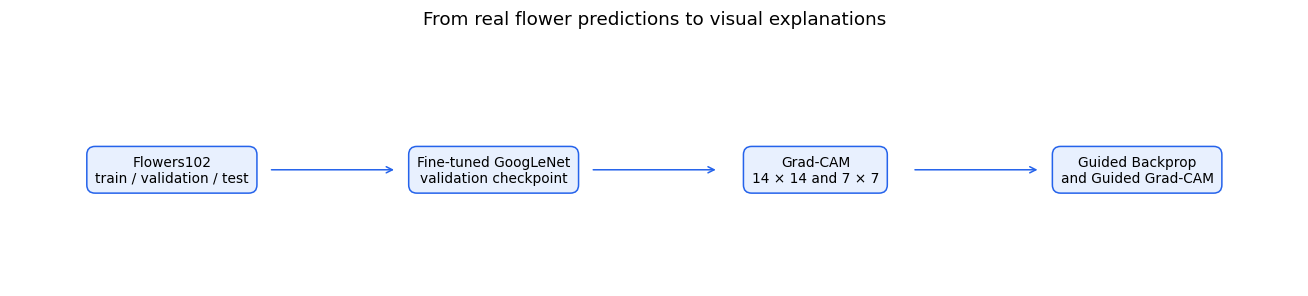

In [2]:
diagram(['Flowers102\ntrain / validation / test','Fine-tuned GoogLeNet\nvalidation checkpoint','Grad-CAM\n14 × 14 and 7 × 7','Guided Backprop\nand Guided Grad-CAM'],'From real flower predictions to visual explanations')

## Data and evaluation design

The official splits contain 1,020 training, 1,020 validation, and 6,149 test images across 102 classes. Training uses spatial and color augmentation; validation and explanation images use deterministic resizing and cropping. All tensors use ImageNet normalization.

The pretrained weights and benchmark split files are verified before use. The test images never select the checkpoint.

In [3]:
# Build the torchvision layout from attached images and verified benchmark metadata.
from pathlib import Path
import shutil, hashlib
base = Path('/tmp/coursework-data/flowers-102')
base.mkdir(parents=True, exist_ok=True)
image_matches = list(Path('/kaggle/input').rglob('image_00001.jpg'))
if len(image_matches) != 1:
    raise RuntimeError(f'Expected one Flowers102 image collection; found {len(image_matches)}')
images = image_matches[0].parent
if len(list(images.glob('image_*.jpg'))) != 8189:
    raise RuntimeError('The Flowers102 image collection is incomplete.')
if not (base/'jpg').exists():
    (base/'jpg').symlink_to(images, target_is_directory=True)
checksums = {'imagelabels.mat':'e0620be6f572b9609742df49c70aed4d',
             'setid.mat':'a5357ecc9cb78c4bef273ce3793fc85c'}
for filename, checksum in checksums.items():
    matches = [p for p in Path('/kaggle/input').rglob(filename)
               if hashlib.md5(p.read_bytes()).hexdigest() == checksum]
    if not matches:
        raise RuntimeError(f'Missing verified Flowers102 metadata: {filename}')
    shutil.copy2(matches[0], base/filename)
weights = next(Path('/kaggle/input').rglob('googlenet-1378be20.pth'))
if not hashlib.sha256(weights.read_bytes()).hexdigest().startswith('1378be20'):
    raise RuntimeError('Pretrained weight checksum mismatch.')
weight_cache = Path(torch.hub.get_dir())/'checkpoints'
weight_cache.mkdir(parents=True, exist_ok=True)
shutil.copy2(weights, weight_cache/weights.name)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ── Augmented transform for TRAINING ──────────────────────────────────────
transform_train = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),   # random crop
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.3, contrast=0.3,
                           saturation=0.3, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# ── Clean transform for VAL / TEST / XAI ──────────────────────────────────
transform_eval = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

def denormalize(t):
    m = torch.tensor(IMAGENET_MEAN).view(3,1,1)
    s = torch.tensor(IMAGENET_STD).view(3,1,1)
    return (t * s + m).clamp(0, 1)

{'training': 1020, 'validation': 1020, 'test': 6149}


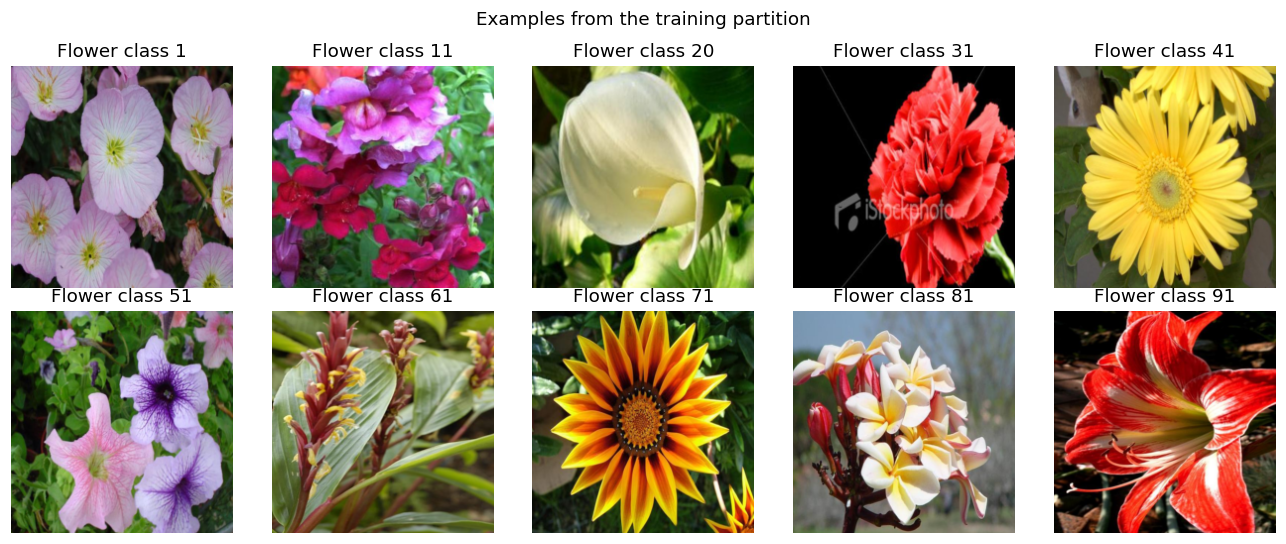

In [4]:
NUM_CLASSES=102
DATA_DIR='/tmp/coursework-data'
train_aug=datasets.Flowers102(DATA_DIR,split='train',download=False,transform=transform_train)
train_clean=datasets.Flowers102(DATA_DIR,split='train',download=False,transform=transform_eval)
val_clean=datasets.Flowers102(DATA_DIR,split='val',download=False,transform=transform_eval)
test_full=datasets.Flowers102(DATA_DIR,split='test',download=False,transform=transform_eval)
train_loader=DataLoader(train_aug,batch_size=32,shuffle=True,num_workers=0)
val_loader=DataLoader(val_clean,batch_size=32,shuffle=False,num_workers=0)
test_loader=DataLoader(test_full,batch_size=32,shuffle=False,num_workers=0)
print({'training':len(train_aug),'validation':len(val_clean),'test':len(test_full)})
fig,axes=plt.subplots(2,5,figsize=(12,5))
for i,ax in enumerate(axes.flat):
 image,label=train_clean[i*100];ax.imshow(denormalize(image).permute(1,2,0));ax.set_title(f'Flower class {label+1}');ax.axis('off')
fig.suptitle('Examples from the training partition');plt.tight_layout();plt.show()

## Warm-up and fine-tuning

I train the three classifier heads for five epochs, then unfreeze the model for 25 further epochs. The warm-up freezes backbone parameters and batch-normalization running statistics. Auxiliary classifier branches are randomly initialized by torchvision; their hidden layers are fixed during warm-up and train during fine-tuning.

Fine-tuning uses mixup (α = 0.4), label smoothing (0.1), and cosine learning-rate decay. The mixup accuracy below weights correctness against both mixed labels; it is a training diagnostic, not accuracy on natural images. Training objective includes auxiliary losses; validation loss uses the main classifier only.

In [5]:
def build_googlenet(nc=102):
    m = models.googlenet(weights=GoogLeNet_Weights.DEFAULT, aux_logits=True)
    m.fc       = nn.Linear(m.fc.in_features, nc)
    m.aux1.fc2 = nn.Linear(m.aux1.fc2.in_features, nc)
    m.aux2.fc2 = nn.Linear(m.aux2.fc2.in_features, nc)
    return m

def freeze_backbone(model):
    """Freeze all layers except the three classifier heads."""
    for p in model.parameters(): p.requires_grad = False
    for p in model.fc.parameters():       p.requires_grad = True
    for p in model.aux1.fc2.parameters(): p.requires_grad = True
    for p in model.aux2.fc2.parameters(): p.requires_grad = True

def unfreeze_all(model):
    """Unfreeze every parameter."""
    for p in model.parameters(): p.requires_grad = True

def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print('Model builder defined.')
def mixup_batch(x, y, alpha=0.4):
    """Apply Mixup augmentation to a batch."""
    if alpha <= 0: return x, y, y, 1.0
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(x.size(0), device=x.device)
    x_mix  = lam * x + (1 - lam) * x[idx]
    y_a, y_b = y, y[idx]
    return x_mix, y_a, y_b, lam

def mixup_loss(criterion, logits, y_a, y_b, lam):
    return lam * criterion(logits, y_a) + (1 - lam) * criterion(logits, y_b)

print('Mixup utilities defined.')

Model builder defined.
Mixup utilities defined.


In [6]:
def run_epoch(model, loader, criterion, optimizer=None, use_mixup=False):
    training = optimizer is not None
    model.train() if training else model.eval()
    if training and getattr(model,'freeze_statistics',False):
        for layer in model.modules():
            if isinstance(layer,nn.BatchNorm2d):layer.eval()
    ls, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            if training: optimizer.zero_grad()
            # Mixup only during training
            if training and use_mixup:
                inputs, y_a, y_b, lam = mixup_batch(inputs, labels)
            outs = model(inputs)
            if training:
                logits = outs.logits
                if use_mixup:
                    loss = mixup_loss(criterion, logits, y_a, y_b, lam)
                    if outs.aux_logits1 is not None:
                        loss += 0.3 * mixup_loss(criterion, outs.aux_logits1, y_a, y_b, lam)
                    if outs.aux_logits2 is not None:
                        loss += 0.3 * mixup_loss(criterion, outs.aux_logits2, y_a, y_b, lam)
                else:
                    loss = criterion(logits, labels)
                    if outs.aux_logits1 is not None: loss += 0.3 * criterion(outs.aux_logits1, labels)
                    if outs.aux_logits2 is not None: loss += 0.3 * criterion(outs.aux_logits2, labels)
                loss.backward(); optimizer.step()
            else:
                logits = outs
                loss = criterion(logits, labels)
            ls      += loss.item() * labels.size(0)
            # For accuracy, use original labels (not mixed)
            preds    = logits.argmax(1)
            ref_lbl  = labels
            if training and use_mixup:
                correct += (lam*(preds==y_a).float()+(1-lam)*(preds==y_b).float()).sum().item()
            else:correct += (preds == ref_lbl).sum().item()
            total   += labels.size(0)
    return ls / total, correct / total

print('Training utilities ready.')

Training utilities ready.


/usr/local/lib/python3.13/dist-packages/torchvision/models/googlenet.py:341: UserWarning: auxiliary heads in the pretrained googlenet model are NOT pretrained, so make sure to train them
  warnings.warn(


Epoch 01/30 | training objective 7.4545 | validation loss 4.1092 | validation accuracy 25.10%


Epoch 02/30 | training objective 6.6091 | validation loss 3.5553 | validation accuracy 43.14%


Epoch 03/30 | training objective 6.0343 | validation loss 3.1714 | validation accuracy 55.88%


Epoch 04/30 | training objective 5.5969 | validation loss 2.8663 | validation accuracy 63.14%


...

Epoch 28/30 | training objective 3.6134 | validation loss 1.5086 | validation accuracy 86.37%


Epoch 29/30 | training objective 3.8022 | validation loss 1.5247 | validation accuracy 85.69%


Epoch 30/30 | training objective 3.6984 | validation loss 1.4874 | validation accuracy 86.96%


Selected epoch: 30


,epoch,training_objective,training_accuracy_diagnostic,validation_loss,validation_accuracy,learning_rate
25,26,3.917211,0.768971,1.523115,0.858824,0.000010
26,27,3.644830,0.822740,1.504344,0.862745,0.000007
27,28,3.613443,0.821904,1.508624,0.863725,0.000004
28,29,3.802237,0.780909,1.524679,0.856863,0.000003
29,30,3.698440,0.802367,1.487398,0.869608,0.000001


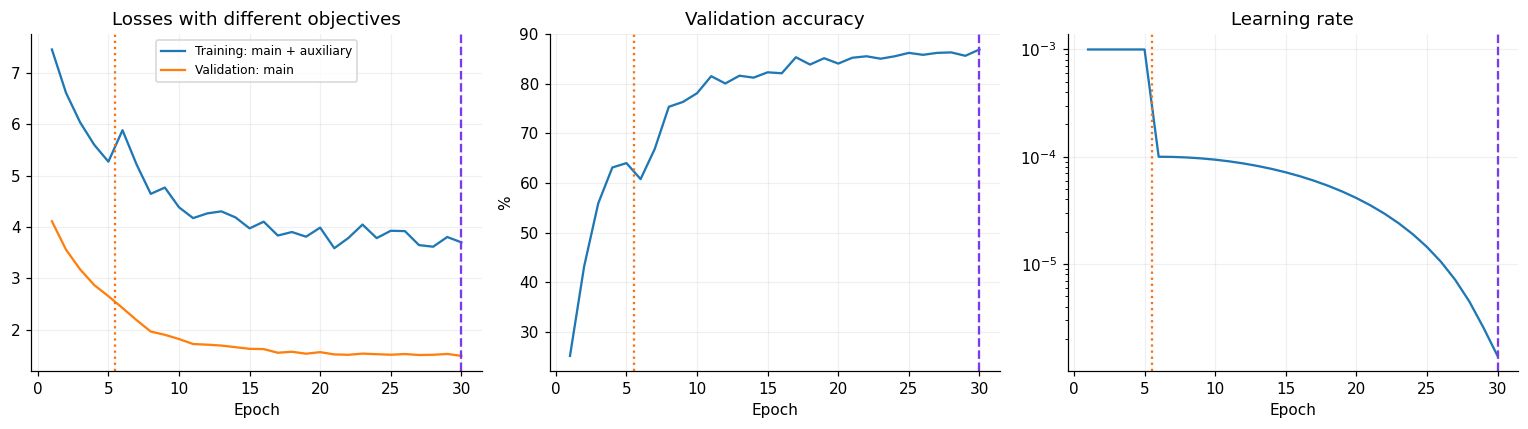

In [7]:
WARMUP_EPOCHS=5;FINETUNE_EPOCHS=25
model=build_googlenet(NUM_CLASSES).to(device)
criterion=nn.CrossEntropyLoss(label_smoothing=.1)
freeze_backbone(model);model.freeze_statistics=True
optimizer=optim.Adam(filter(lambda p:p.requires_grad,model.parameters()),lr=1e-3)
best_loss=float('inf');best_state=None;best_epoch=None;history=[]
start=time.perf_counter()
for epoch in range(1,31):
 if epoch==6:
  unfreeze_all(model);model.freeze_statistics=False
  optimizer=optim.Adam(model.parameters(),lr=1e-4,weight_decay=1e-4)
  scheduler=optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=25,eta_min=1e-6)
 lr=optimizer.param_groups[0]['lr']
 tl,ta=run_epoch(model,train_loader,criterion,optimizer,use_mixup=epoch>5)
 vl,va=run_epoch(model,val_loader,criterion)
 history.append({'epoch':epoch,'training_objective':tl,'training_accuracy_diagnostic':ta,'validation_loss':vl,'validation_accuracy':va,'learning_rate':lr})
 if vl<best_loss:best_loss=vl;best_epoch=epoch;best_state=copy.deepcopy(model.state_dict())
 if epoch>5:scheduler.step()
 print(f'Epoch {epoch:02d}/30 | training objective {tl:.4f} | validation loss {vl:.4f} | validation accuracy {va:.2%}',flush=True)
training_seconds=time.perf_counter()-start
model.load_state_dict(best_state);model.eval()
history=pd.DataFrame(history);print('Selected epoch:',best_epoch)
display(history.tail())
fig,axes=plt.subplots(1,3,figsize=(14,4))
axes[0].plot(history.epoch,history.training_objective,label='Training: main + auxiliary');axes[0].plot(history.epoch,history.validation_loss,label='Validation: main');axes[0].set(title='Losses with different objectives',xlabel='Epoch');axes[0].legend(fontsize=8)
axes[1].plot(history.epoch,history.validation_accuracy*100);axes[1].set(title='Validation accuracy',xlabel='Epoch',ylabel='%')
axes[2].semilogy(history.epoch,history.learning_rate);axes[2].set(title='Learning rate',xlabel='Epoch')
for ax in axes:ax.axvline(5.5,color='#f97316',ls=':',label='Unfreeze');ax.axvline(best_epoch,color='#7c3aed',ls='--')
plt.tight_layout();plt.show()

## Test evaluation and diverse explanation examples

After restoring the lowest-validation-loss checkpoint, I evaluate all 6,149 test images. I then choose the first correctly classified image from each of four different true classes and the first error in dataset order. These choices are deterministic and deliberately include both correct and incorrect predictions. Class labels in figures are one-based identifiers, not species names.

Full-test accuracy: 84.00%; macro F1: 0.8270


,test_index,true_class,predicted_class,predicted_probability,correct
0,1,1,1,0.524924,True
1,20,2,2,0.547414,True
2,63,3,3,0.342341,True
3,83,4,4,0.294975,True
4,0,1,19,0.176879,False


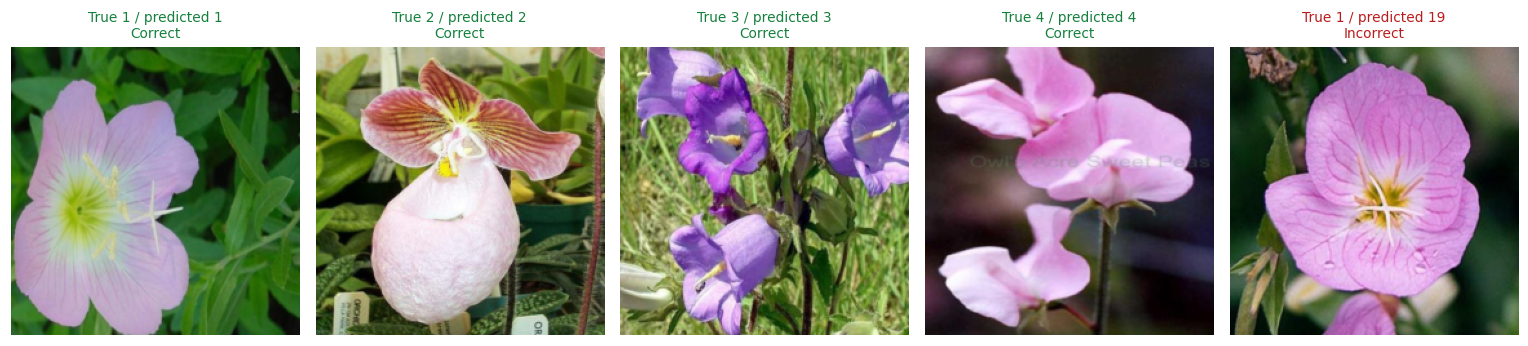

In [8]:
test_logits=[];test_labels=[]
with torch.no_grad():
 for images,labels in test_loader:
  test_logits.append(model(images.to(device)).cpu());test_labels.append(labels)
test_logits=torch.cat(test_logits);test_labels=torch.cat(test_labels);test_predictions=test_logits.argmax(1)
test_accuracy=accuracy_score(test_labels,test_predictions);test_macro_f1=f1_score(test_labels,test_predictions,average='macro')
print(f'Full-test accuracy: {test_accuracy:.2%}; macro F1: {test_macro_f1:.4f}')
correct_indices=[];seen=set()
for index in torch.where(test_predictions==test_labels)[0].tolist():
 label=int(test_labels[index])
 if label not in seen:correct_indices.append(index);seen.add(label)
 if len(correct_indices)==4:break
wrong_indices=torch.where(test_predictions!=test_labels)[0][:1].tolist()
assert len(correct_indices)==4 and len(wrong_indices)==1
selected_indices=correct_indices+wrong_indices;N=len(selected_indices)
selected_images=[test_full[i][0] for i in selected_indices]
selected_labels=[int(test_labels[i]) for i in selected_indices];selected_preds=[int(test_predictions[i]) for i in selected_indices]
selected_probabilities=test_logits[selected_indices].softmax(1);correct=[p==y for p,y in zip(selected_preds,selected_labels)]
selection=pd.DataFrame({'test_index':selected_indices,'true_class':[y+1 for y in selected_labels],'predicted_class':[p+1 for p in selected_preds],'predicted_probability':[float(selected_probabilities[i,p]) for i,p in enumerate(selected_preds)],'correct':correct});display(selection)
fig,axes=plt.subplots(1,N,figsize=(14,3.6))
for i,ax in enumerate(axes):
 ax.imshow(denormalize(selected_images[i]).permute(1,2,0));ax.set_title(f'True {selected_labels[i]+1} / predicted {selected_preds[i]+1}\n'+('Correct' if correct[i] else 'Incorrect'),color='#15803d' if correct[i] else '#b91c1c',fontsize=9);ax.axis('off')
plt.tight_layout();plt.show()
# Retain a reusable cloud checkpoint; large weights are excluded from the GitHub repository.
torch.save({'state_dict':model.state_dict(),'best_validation_epoch':best_epoch,'transform_input':model.transform_input,'num_classes':102},'googlenet_flowers102_validation_checkpoint.pth')

## Grad-CAM from the target-class gradient

For target logit y and activation map A, I average ∂y/∂A over spatial positions to obtain a weight per channel. The ReLU of their weighted sum gives the positive class-localization map. I normalize only for display and upsample bilinearly to the input size.

A temporary forward hook captures each layer output. `torch.autograd.grad` obtains its gradients directly, and the hook is removed in a `finally` block. This avoids accumulating hooks or altering backward behavior. I check the unnormalized result against Captum's LayerGradCam on both layers.

Native map sizes: {'inception4e': [14, 14], 'inception5b': [7, 7]} Max Captum reference differences: {'inception4e': 1.862645149230957e-09, 'inception5b': 0.0}


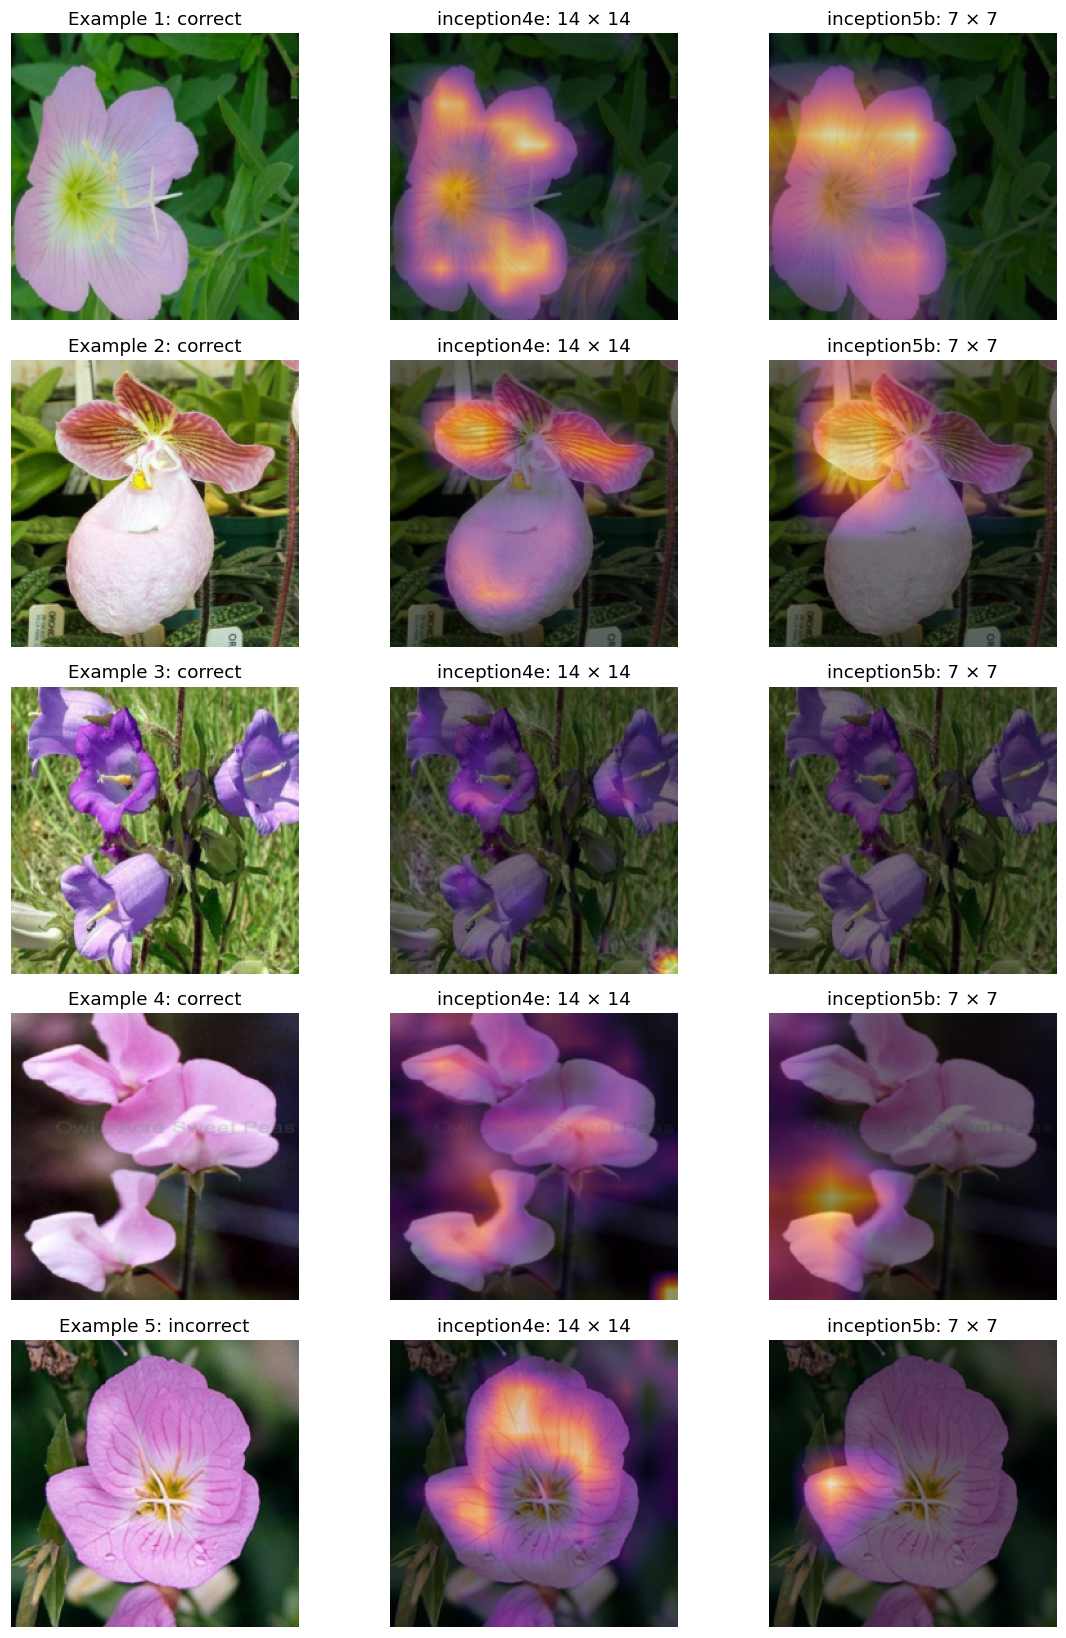

In [9]:
class GradCAM:
 def __init__(self,model,target_layer):self.model=model;self.target_layer=target_layer
 def generate(self,image,target):
  captured={}
  handle=self.target_layer.register_forward_hook(lambda module,inputs,output:captured.update(activation=output))
  try:
   with torch.enable_grad():
    x=image.detach().clone().requires_grad_(True);logits=self.model(x);activation=captured['activation']
    gradient=torch.autograd.grad(logits[0,target],activation)[0]
    weights=gradient.mean(dim=(2,3),keepdim=True)
    raw=torch.relu((weights*activation).sum(dim=1,keepdim=True)).detach()
   upsampled=F.interpolate(raw,size=(224,224),mode='bilinear',align_corners=False)
   normalized=upsampled/(upsampled.amax()+1e-12)
   assert torch.isfinite(normalized).all()
   return {'raw':raw,'upsampled':upsampled,'display':normalized[0,0].cpu().numpy(),'native_shape':list(raw.shape[-2:])}
  finally:handle.remove()
gradcam={name:GradCAM(model,getattr(model,name)) for name in ['inception4e','inception5b']}
cam_results={name:[] for name in gradcam};native_shapes={};reference_errors={};timings=[]
for i,(image,target) in enumerate(zip(selected_images,selected_preds)):
 x=image[None].to(device)
 for name,explainer in gradcam.items():
  torch.cuda.synchronize();start=time.perf_counter();result=explainer.generate(x,target);torch.cuda.synchronize()
  timings.append({'example':i+1,'layer':name,'seconds':time.perf_counter()-start});cam_results[name].append(result);native_shapes[name]=result['native_shape']
  if i==0:
   ref=LayerGradCam(model,getattr(model,name)).attribute(x.detach().clone().requires_grad_(True),target=target,relu_attributions=True)
   torch.testing.assert_close(result['raw'],ref.detach(),rtol=1e-4,atol=1e-6)
   reference_errors[name]=float((result['raw']-ref.detach()).abs().max())
print('Native map sizes:',native_shapes,'Max Captum reference differences:',reference_errors)
assert native_shapes=={'inception4e':[14,14],'inception5b':[7,7]}
fig,axes=plt.subplots(N,3,figsize=(11,3*N))
for i in range(N):
 visual=denormalize(selected_images[i]).permute(1,2,0)
 axes[i,0].imshow(visual);axes[i,0].set_title(f'Example {i+1}: '+('correct' if correct[i] else 'incorrect'))
 for j,name in enumerate(gradcam,1):
  axes[i,j].imshow(visual);axes[i,j].imshow(cam_results[name][i]['display'],cmap='inferno',vmin=0,vmax=1,alpha=.55);axes[i,j].set_title(f'{name}: {native_shapes[name][0]} × {native_shapes[name][1]}')
 for ax in axes[i]:ax.axis('off')
plt.tight_layout();plt.show()

## Native resolution versus interpolation

The intermediate inception4e maps have 14 × 14 locations; inception5b has 7 × 7. Enlarging either to 224 × 224 does not create new localization information. Each map is normalized independently for visualization, so brightness cannot be compared as an absolute attribution magnitude across classes or layers.

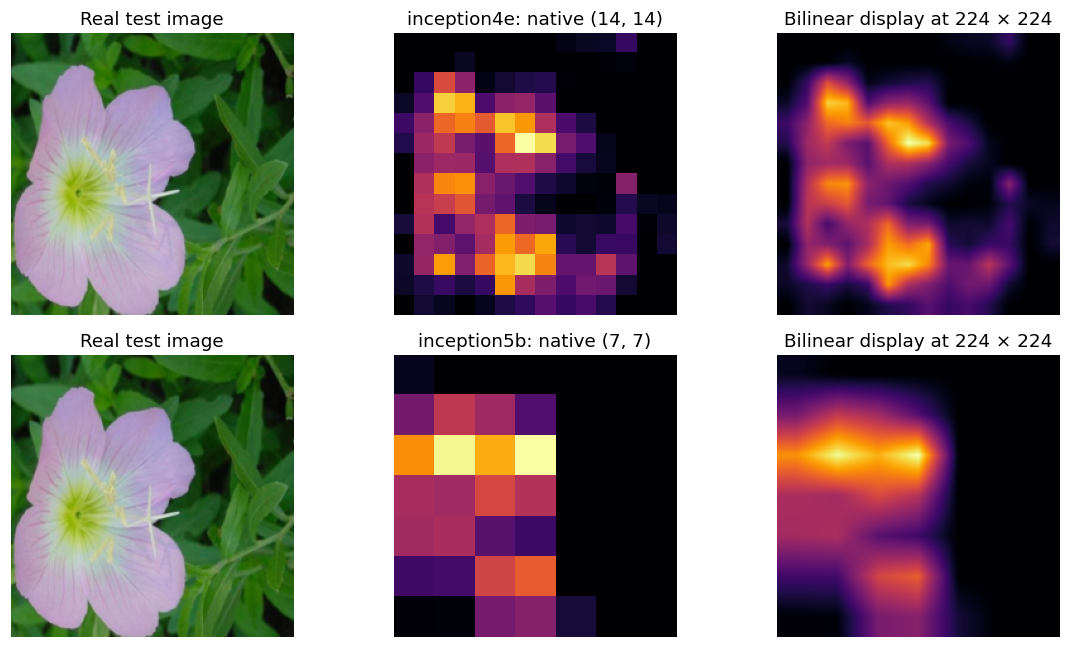

In [10]:
fig,axes=plt.subplots(2,3,figsize=(11,6))
for row,name in enumerate(gradcam):
 result=cam_results[name][0];raw=result['raw'][0,0].cpu().numpy();raw=raw/(raw.max()+1e-12)
 axes[row,0].imshow(denormalize(selected_images[0]).permute(1,2,0));axes[row,0].set_title('Real test image')
 axes[row,1].imshow(raw,cmap='inferno',vmin=0,vmax=1,interpolation='nearest');axes[row,1].set_title(f'{name}: native {raw.shape}')
 axes[row,2].imshow(result['display'],cmap='inferno',vmin=0,vmax=1);axes[row,2].set_title('Bilinear display at 224 × 224')
 for ax in axes[row]:ax.axis('off')
plt.tight_layout();plt.show()

## Comparing target classes for an incorrect prediction

For the selected error, I compute maps for the true class, predicted class, and runner-up logit. This changes the target being differentiated while keeping the image and model fixed. It is a target-class comparison; no image is edited, so it is not a counterfactual intervention. Heatmaps can suggest areas to inspect, but cannot establish that background clutter or visual similarity caused an error.

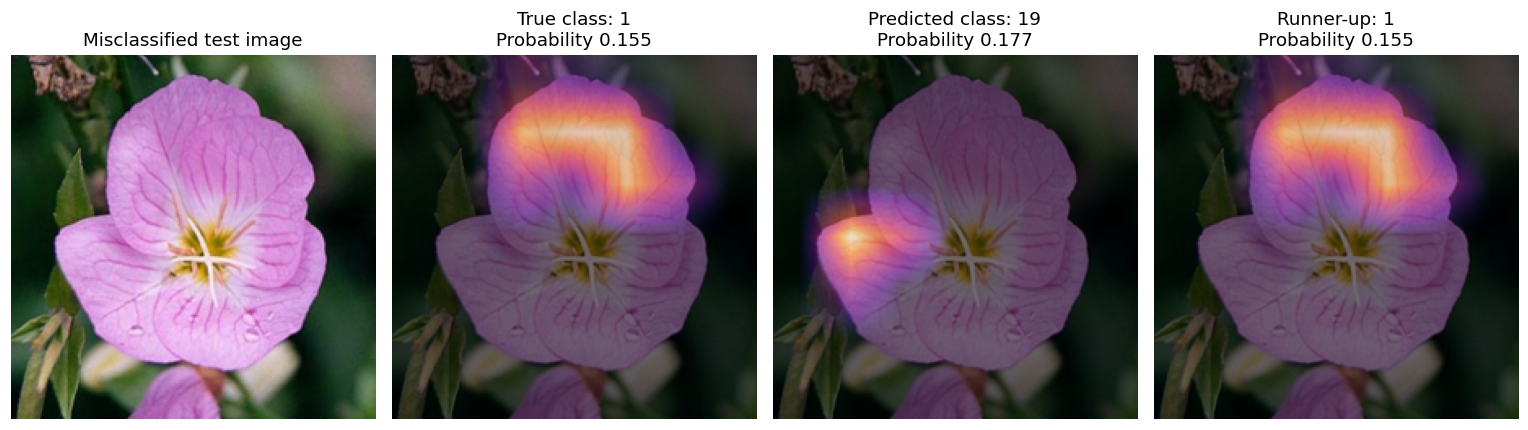

,role,class_id_one_based,probability,native_cam_max
0,True class,1,0.155304,0.025840
1,Predicted class,19,0.176879,0.014909
2,Runner-up,1,0.155304,0.025840


In [11]:
error_index=N-1;image=selected_images[error_index];x=image[None].to(device)
true_class=selected_labels[error_index];predicted_class=selected_preds[error_index]
runner_up=int(test_logits[selected_indices[error_index]].topk(2).indices[1])
targets=[('True class',true_class),('Predicted class',predicted_class),('Runner-up',runner_up)]
target_comparison=[];fig,axes=plt.subplots(1,4,figsize=(14,4))
visual=denormalize(image).permute(1,2,0);axes[0].imshow(visual);axes[0].set_title('Misclassified test image')
for ax,(label,target) in zip(axes[1:],targets):
 result=gradcam['inception5b'].generate(x,target);prob=float(selected_probabilities[error_index,target])
 ax.imshow(visual);ax.imshow(result['display'],cmap='inferno',vmin=0,vmax=1,alpha=.55);ax.set_title(f'{label}: {target+1}\nProbability {prob:.3f}')
 target_comparison.append({'role':label,'class_id_one_based':target+1,'probability':prob,'native_cam_max':float(result['raw'].max())})
for ax in axes:ax.axis('off')
plt.tight_layout();plt.show();display(pd.DataFrame(target_comparison))

## Making Guided Backpropagation valid for GoogLeNet

Torchvision's convolution blocks use functional ReLU, whereas Captum GuidedBackprop requires `nn.ReLU` modules so it can modify their backward rule. I copy the trained network and replace the active convolution-block ReLU calls with explicit non-inplace modules. The weights remain identical, and I verify identical evaluation logits before computing guided gradients. Auxiliary classifier branches are inactive in evaluation mode.

Guided Grad-CAM multiplies raw Guided Backpropagation by the upsampled positive Grad-CAM. I apply display normalization after this multiplication, and compare the result with Captum's GuidedGradCam implementation. High-frequency detail is not evidence of greater faithfulness.

Converted ReLU blocks: 59 Maximum logit difference: 0.0
Maximum Guided Grad-CAM reference difference: 2.9103830456733704e-10


/usr/local/lib/python3.13/dist-packages/captum/attr/_core/guided_backprop_deconvnet.py:66: UserWarning: Setting backward hooks on ReLU activations.The hooks will be removed after the attribution is finished
  warnings.warn(


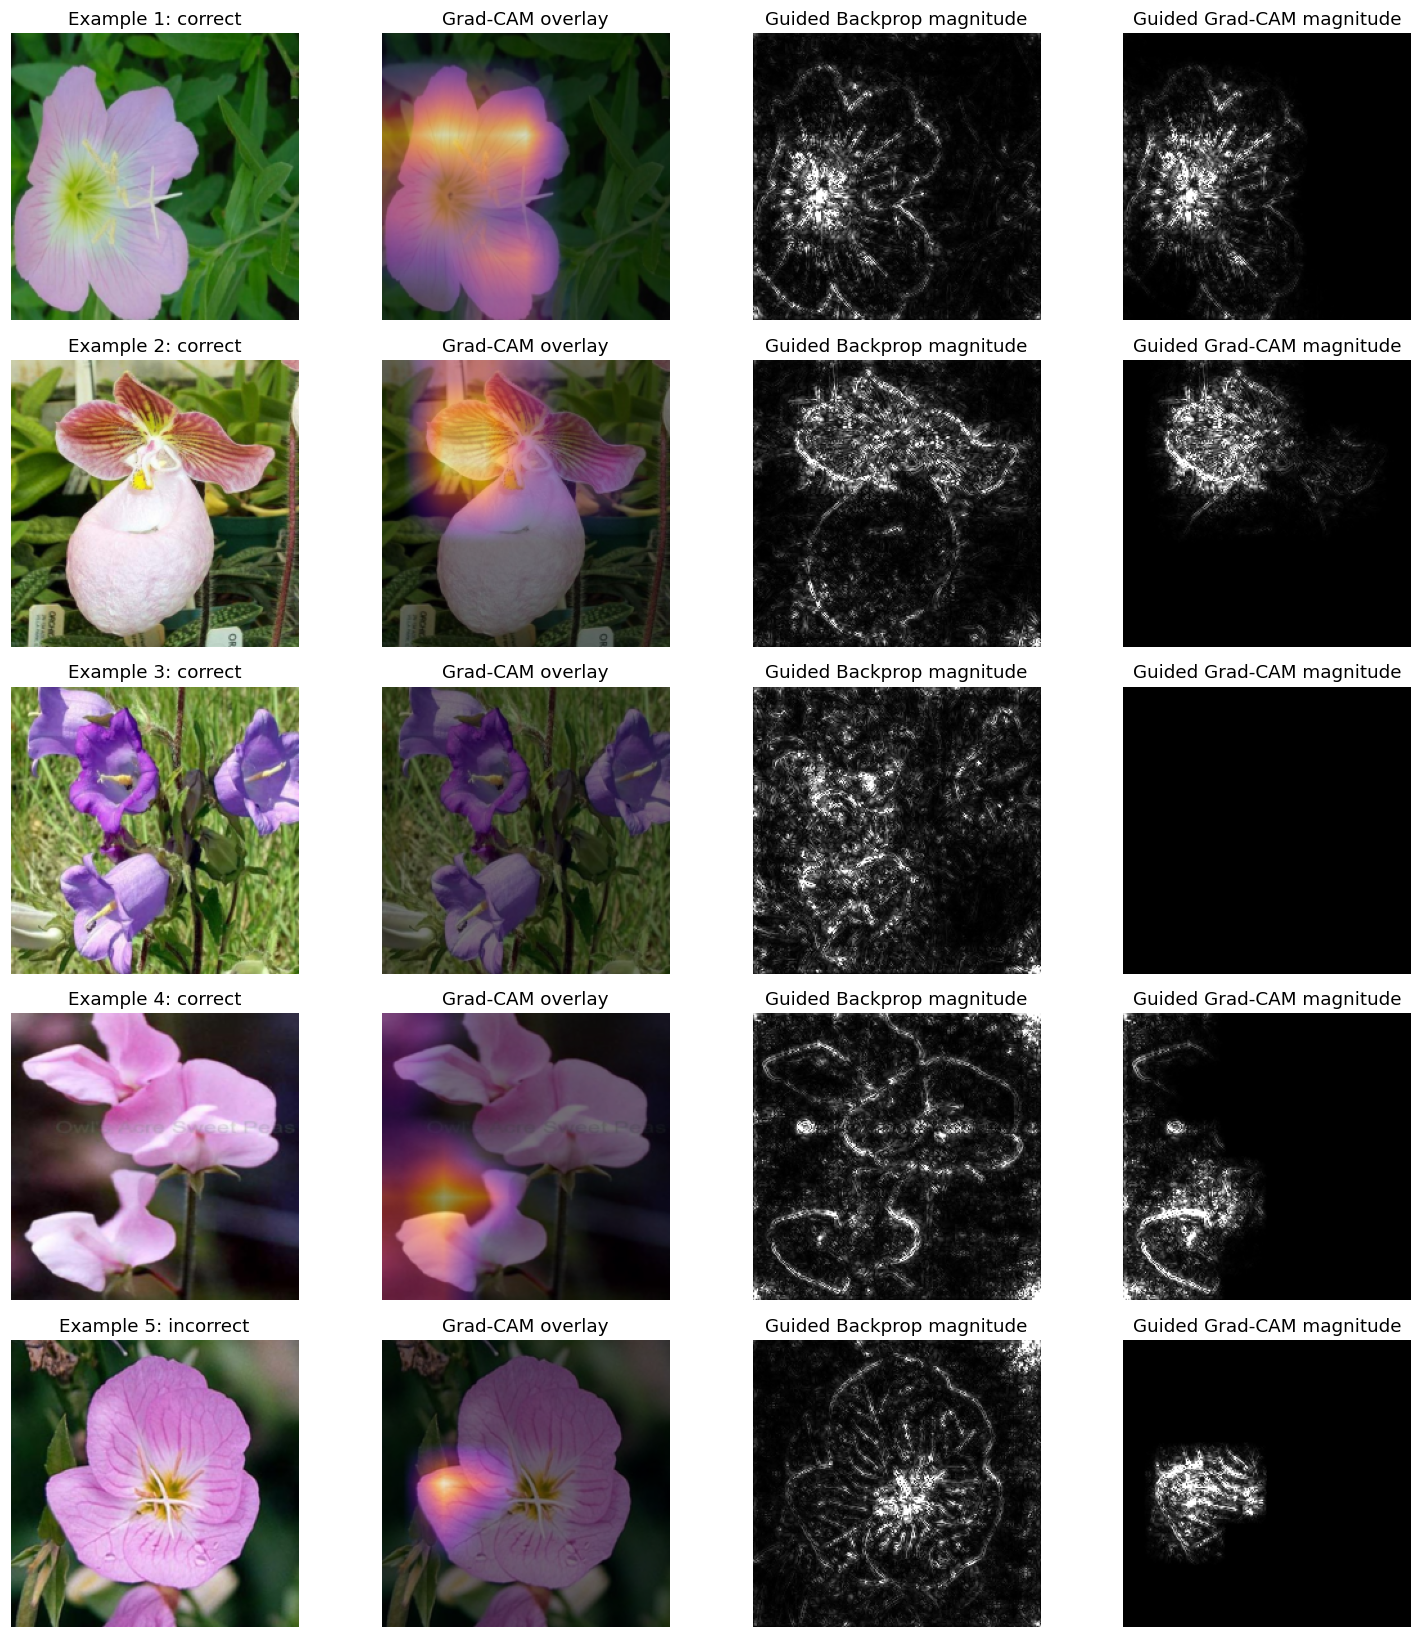

In [12]:
guided_model=copy.deepcopy(model).eval()
with torch.no_grad():original_logits=model(torch.stack(selected_images).to(device))
def module_relu_forward(self,x):return self.guided_relu(self.bn(self.conv(x)))
replaced=0
for block in list(guided_model.modules()):
 if isinstance(block,BasicConv2d):
  block.guided_relu=nn.ReLU(inplace=False);block.forward=types.MethodType(module_relu_forward,block);replaced+=1
with torch.no_grad():patched_logits=guided_model(torch.stack(selected_images).to(device))
torch.testing.assert_close(original_logits,patched_logits,rtol=1e-5,atol=1e-6)
logit_difference=float((original_logits-patched_logits).abs().max())
print('Converted ReLU blocks:',replaced,'Maximum logit difference:',logit_difference)
guided=GuidedBackprop(guided_model);guided_maps=[];guided_backprop=[]
guided_reference_error=None
for i,(image,target) in enumerate(zip(selected_images,selected_preds)):
 x=image[None].to(device).requires_grad_(True)
 gb=guided.attribute(x,target=target).detach()
 gg=gb*cam_results['inception5b'][i]['upsampled']
 assert gg.shape==(1,3,224,224) and torch.isfinite(gg).all()
 if i==0:
  ref=GuidedGradCam(guided_model,guided_model.inception5b).attribute(x,target=target,interpolate_mode='bilinear')
  torch.testing.assert_close(gg,ref.detach(),rtol=1e-4,atol=1e-6);guided_reference_error=float((gg-ref.detach()).abs().max())
 guided_backprop.append(gb[0].cpu().numpy());guided_maps.append(gg[0].cpu().numpy())
print('Maximum Guided Grad-CAM reference difference:',guided_reference_error)
def magnitude_display(array):
 magnitude=np.abs(array).sum(axis=0);scale=max(float(np.percentile(magnitude,99)),1e-12)
 return np.clip(magnitude/scale,0,1)
fig,axes=plt.subplots(N,4,figsize=(14,3*N))
for i in range(N):
 visual=denormalize(selected_images[i]).permute(1,2,0);axes[i,0].imshow(visual);axes[i,0].set_title(f'Example {i+1}: '+('correct' if correct[i] else 'incorrect'))
 axes[i,1].imshow(visual);axes[i,1].imshow(cam_results['inception5b'][i]['display'],cmap='inferno',vmin=0,vmax=1,alpha=.55);axes[i,1].set_title('Grad-CAM overlay')
 axes[i,2].imshow(magnitude_display(guided_backprop[i]),cmap='gray',vmin=0,vmax=1);axes[i,2].set_title('Guided Backprop magnitude')
 axes[i,3].imshow(magnitude_display(guided_maps[i]),cmap='gray',vmin=0,vmax=1);axes[i,3].set_title('Guided Grad-CAM magnitude')
 for ax in axes[i]:ax.axis('off')
plt.tight_layout();plt.show()

## What the methods measure

Grad-CAM assigns target-logit weights to feature maps and gives coarse spatial localization. Guided Backpropagation produces a modified input gradient, while Guided Grad-CAM combines its detail with class-localization weights. The grayscale displays show absolute attribution magnitude, so they do not retain sign.

The earlier explainability coursework used occlusion and SHAP. Occlusion measures a probability change after perturbing a region; SHAP here used expected gradients relative to training backgrounds. Those quantities have different units and assumptions. I do not rank them using unmeasured runtime or visual sharpness, and these five hand-selected images do not validate explanation faithfulness.

,example,layer,seconds
0,1,inception4e,0.157729
1,1,inception5b,0.012954
2,2,inception4e,0.010726
3,2,inception5b,0.009273
4,3,inception4e,0.010968
5,3,inception5b,0.009279
6,4,inception4e,0.010369
7,4,inception5b,0.008952
8,5,inception4e,0.010344
9,5,inception5b,0.009168


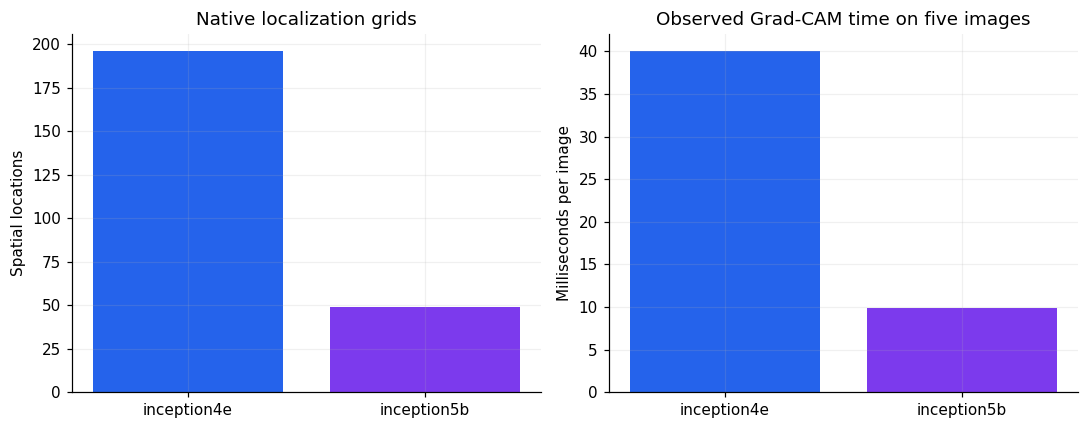

In [13]:
timings=pd.DataFrame(timings)
display(timings)
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].bar(['inception4e','inception5b'],[14*14,7*7],color=['#2563eb','#7c3aed']);axes[0].set(title='Native localization grids',ylabel='Spatial locations')
means=timings.groupby('layer').seconds.mean();axes[1].bar(means.index,means.values*1000,color=['#2563eb','#7c3aed']);axes[1].set(title='Observed Grad-CAM time on five images',ylabel='Milliseconds per image')
plt.tight_layout();plt.show()
result={'test_accuracy':float(test_accuracy),'test_macro_f1':float(test_macro_f1),'best_validation_epoch':int(best_epoch),'best_validation_loss':float(best_loss),'epochs':30,'train_images':len(train_aug),'validation_images':len(val_clean),'test_images':len(test_full),'training_seconds':training_seconds,'gpu':torch.cuda.get_device_name(0),'selected_examples':selection.to_dict('records'),'native_map_shapes':native_shapes,'gradcam_reference_max_errors':reference_errors,'converted_relu_blocks':replaced,'relu_conversion_max_logit_difference':logit_difference,'guided_gradcam_reference_max_error':guided_reference_error,'target_comparison':target_comparison}
Path('results.json').write_text(json.dumps(result,indent=2));history.to_csv('training_history.csv',index=False);selection.to_csv('selected_examples.csv',index=False);timings.to_csv('gradcam_timings.csv',index=False)

## What I learned

Real inputs and a verified trained checkpoint are prerequisites for interpreting a classifier's behavior. Native feature-map resolution limits localization even when the display looks smooth. Comparing true and predicted targets changes the explanation without changing the image. Library assumptions matter: functional ReLU must be handled explicitly for Guided Backpropagation.

Maps provide hypotheses to investigate, not proof of causal failure mechanisms. Checkpoint selection and evaluation remain separate, and this single run does not measure variability across seeds.

References: [Grad-CAM paper](https://arxiv.org/abs/1610.02391) · [Captum Guided Backpropagation](https://captum.ai/api/guided_backprop.html) · [Captum Guided Grad-CAM](https://captum.ai/api/guided_grad_cam.html) · [torchvision GoogLeNet source](https://github.com/pytorch/vision/blob/main/torchvision/models/googlenet.py).

## Measured findings

The checkpoint selected at epoch **30** achieved **84.00%** full-test accuracy and **0.8270** macro F1. The explanation examples contain four correct predictions from different true classes and one error. Native localization maps have **14 × 14** and **7 × 7** spatial locations. The ReLU conversion changed evaluation logits by at most **0.00e+00**; both explanation implementations passed their reference comparisons. These checks validate implementation consistency, not explanation faithfulness.

The third Guided Grad-CAM display is nearly blank even though the prediction is correct. This is a limitation of the displayed explanation, and it is retained rather than treated as evidence that every correct prediction has a clear localization map.